# Etapa 2: Modelagem de Tópicos Neural (BERTopic) e Análise Longitudinal (2010–2024)

Neste notebook, avançamos para a etapa de **Mineração de Dados (Data Mining)** do processo KDD, com foco nos objetivos do artigo para o **Educomp**:
1. **Descoberta Não Supervisionada de Subáreas:** Agrupar semanticamente as teses e dissertações de Ciência da Computação no Brasil (2010–2024) usando representações neurais densas (*Sentence Embeddings* via PyTorch/Transformers) + redução de dimensionalidade (**UMAP**) + clusterização baseada em densidade (**HDBSCAN**).
2. **Rastreamento Temporal da Inteligência Artificial:** Mapear a evolução longitudinal dos tópicos ano a ano (`topics_over_time`) para detectar o ponto de inflexão das pesquisas em IA, Aprendizado de Máquina, Redes Neurais e Ciência de Dados.
3. **Análise de Disparidades Regionais e Nível Acadêmico:** Investigar como a produção em IA se distribui entre as regiões brasileiras (`NM_REGIAO`), instituições (`SG_ENTIDADE_ENSINO`) e graus acadêmicos (`NM_GRAU_ACADEMICO` - Mestrado vs. Doutorado).
4. **Rotulagem para Classificação Supervisionada:** Exportar a base enriquecida com os tópicos descobertos e a flag temática de IA para alimentar a Etapa 3 (modelos preditivos).

In [1]:
import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer

sns.set_theme(style="whitegrid")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo de execução PyTorch detectado: {device.upper()}")

Dispositivo de execução PyTorch detectado: CPU


## 1. Carregamento e Preparação da Base Pré-processada
Lemos a base compactada (`dados_capes_nlp_pronto.csv.gz`) gerada na Etapa 1. Como o BERTopic se beneficia tanto do contexto semântico das frases originais (`DS_RESUMO`) para gerar *embeddings* quanto do texto limpo/lematizado (`RESUMO_LIMPO`) para extrair representações de palavras (c-TF-IDF) sem ruído, garantimos que ambas as colunas estejam íntegras.

In [2]:
caminho_entrada = '../data/dados_capes_nlp.csv.gz'
df = pd.read_csv(caminho_entrada, compression='gzip')

# Remove eventuais linhas onde o resumo limpo tenha ficado vazio após o filtro rigoroso
df = df.dropna(subset=['DS_RESUMO', 'RESUMO_LIMPO']).reset_index(drop=True)
df['AN_BASE'] = df['AN_BASE'].astype(int)

print(f"Total de teses e dissertações válidas para modelagem: {len(df)}")
print(f"Período coberto: {df['AN_BASE'].min()} a {df['AN_BASE'].max()}")
df[['AN_BASE', 'SG_ENTIDADE_ENSINO', 'NM_REGIAO', 'NM_GRAU_ACADEMICO', 'NM_PRODUCAO', 'RESUMO_LIMPO']].head(3)

Total de teses e dissertações válidas para modelagem: 22130
Período coberto: 2010 a 2023


,AN_BASE,SG_ENTIDADE_ENSINO,NM_REGIAO,NM_GRAU_ACADEMICO,NM_PRODUCAO,RESUMO_LIMPO
0,2012,UFAM,NORTE,Mestrado,Sistema Inteligente de Recomendação Baseado n...,disseminação curso educação distância frequent...
1,2012,UFAM,NORTE,Mestrado,Alinhamento Espaço-Temporal em Sistemas Multis...,apresentar utilização diferentes sensor aprimo...
2,2012,UFAM,NORTE,Mestrado,''UBICUA: Uma Técnica de Inspeção de Usabilida...,crescente interesse tecnologia móvel evolutivo...


## 2. Geração de Embeddings Semânticos Multilíngues
Muitos resumos da pós-graduação em Computação possuem termos técnicos em inglês misturados ao português. Por isso, utilizamos o modelo `paraphrase-multilingual-MiniLM-L12-v2` via `sentence-transformers`. 

> **Nota Metodológica:** Passamos o `DS_RESUMO` (ou `RESUMO_LIMPO`) para os embeddings. Usar o `RESUMO_LIMPO` acelera a codificação e foca nos conceitos-chave já filtrados na Etapa 1. Salvaremos os vetores em disco (`.npy`) para não precisar recalcular os embeddings caso seja preciso ajustar hiperparâmetros do BERTopic depois.

In [3]:
caminho_embeddings = '../data/embeddings_capes.npy'
modelo_embedding_nome = 'paraphrase-multilingual-MiniLM-L12-v2'
embedding_model = SentenceTransformer(modelo_embedding_nome, device=device)

documentos = df['RESUMO_LIMPO'].tolist()

if os.path.exists(caminho_embeddings):
    print("Carregando embeddings pré-calculados do disco...")
    embeddings = np.load(caminho_embeddings)
else:
    print("Calculando embeddings dos resumos (isso pode levar alguns minutos)...")
    embeddings = embedding_model.encode(
        documentos, 
        show_progress_bar=True, 
        batch_size=64,
        convert_to_numpy=True
    )
    np.save(caminho_embeddings, embeddings)
    print(f"Embeddings salvos com sucesso em {caminho_embeddings}!")

print(f"Formato da matriz de embeddings: {embeddings.shape}")

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Calculando embeddings dos resumos (isso pode levar alguns minutos)...


Batches:   0%|          | 0/346 [00:00<?, ?it/s]

Embeddings salvos com sucesso em ../data/embeddings_capes.npy!
Formato da matriz de embeddings: (22130, 384)


## 3. Configuração e Treinamento da Arquitetura BERTopic
Estruturamos os submódulos do BERTopic de forma explícita para garantir **reprodutibilidade científica** (`random_state=42`) no artigo:
- **UMAP:** Reduz os 384 atributos do embedding para 5 dimensões preservando a estrutura local e global.
- **HDBSCAN:** Agrupa os documentos por densidade sem forçar todos os pontos em clusters artificiais (isolando ruídos no tópico `-1`).
- **CountVectorizer:** Usa unigramas e bigramas (`ngram_range=(1, 2)`) para capturar termos compostos essenciais na Computação, como *"aprendizado máquina"*, *"rede neural"*, *"inteligência artificial"*, *"visão computacional"* e *"engenharia software"*.

In [4]:
# 1. Redução de Dimensionalidade com semente fixa para reprodutibilidade
umap_model = UMAP(
    n_neighbors=15, 
    n_components=5, 
    min_dist=0.0, 
    metric='cosine', 
    random_state=42
)

# 2. Clusterização Hierárquica Baseada em Densidade
# min_cluster_size pode ser ajustado conforme o volume total da base (ex: 50 a 120)
hdbscan_model = HDBSCAN(
    min_cluster_size=80, 
    min_samples=15,
    metric='euclidean', 
    cluster_selection_method='eom', 
    prediction_data=True
)

# 3. Vetorizador c-TF-IDF com suporte a bigramas (termos compostos)
vectorizer_model = CountVectorizer(
    ngram_range=(1, 2), 
    min_df=10
)

# 4. Instanciação e treinamento do BERTopic
topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    nr_topics="auto",         # Agrupa tópicos redundantes automaticamente
    top_n_words=10,
    verbose=True
)

print("Treinando o modelo BERTopic...")
topicos, probabilidades = topic_model.fit_transform(documentos, embeddings)

# Redução opcional de outliers (tópico -1) usando a estratégia de distribuição/embeddings
print("Refinando outliers (tópico -1) para melhorar a cobertura temática...")
novos_topicos = topic_model.reduce_outliers(documentos, topicos, strategy="embeddings", embeddings=embeddings)
topic_model.update_topics(documentos, topics=novos_topicos, vectorizer_model=vectorizer_model)

df['TOPICO_ID'] = novos_topicos
info_topicos = topic_model.get_topic_info()
print(f"\nTotal de tópicos temáticos descobertos (excluindo -1): {len(info_topicos) - 1}")
info_topicos.head(15)

Treinando o modelo BERTopic...


2026-10-24 13:19:53,253 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-24 13:20:42,418 - BERTopic - Dimensionality - Completed ✓
2026-10-24 13:20:42,419 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-24 13:20:46,008 - BERTopic - Cluster - Completed ✓
2026-10-24 13:20:46,009 - BERTopic - Representation - Extracting topics using c-TF-IDF for topic reduction.
2026-10-24 13:20:52,461 - BERTopic - Representation - Completed ✓
2026-10-24 13:20:52,462 - BERTopic - Topic reduction - Reducing number of topics
2026-10-24 13:20:52,483 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-24 13:20:58,903 - BERTopic - Representation - Completed ✓
2026-10-24 13:20:58,906 - BERTopic - Topic reduction - Reduced number of topics from 56 to 38
2026-10-24 13:21:00,694 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure tha

Refinando outliers (tópico -1) para melhorar a cobertura temática...

Total de tópicos temáticos descobertos (excluindo -1): 36


,Topic,Count,Name,Representation,Representative_Docs
0,0,5776,0_algoritmo_resultado_modelo_utilizar,"[algoritmo, resultado, modelo, utilizar, apren...",[problema otimização existir subconjunto probl...
1,1,2413,1_software_teste_projeto_desenvolvimento,"[software, teste, projeto, desenvolvimento, có...",[impacto adoção critério teste desenvolvimento...
2,2,1178,2_paciente_saúde_imagem_doença,"[paciente, saúde, imagem, doença, diagnóstico,...",[nódulo tireóide problema saúde frequente nódu...
3,3,1448,3_rede_dispositivo_internet_iot,"[rede, dispositivo, internet, iot, protocolo, ...",[Internet coisa Internet Things iot conceito c...
4,4,694,4_nuvem_recurso_serviço_computação,"[nuvem, recurso, serviço, computação, virtual,...",[computação nuvem trazer recentemente pequeno ...
5,5,765,5_texto_documento_português_língua,"[texto, documento, português, língua, informaç...",[contínuo expansão coleta disseminação textual...
6,6,561,6_cidade_veículo_urbano_transporte,"[cidade, veículo, urbano, transporte, trânsito...",[mobilidade urbano desafio cidade redor mundo ...
7,7,716,7_social_rede social_rede_usuário,"[social, rede social, rede, usuário, informaçã...",[abordo detecção informação falso instagr rede...
8,8,483,8_gene_sequência_biológico_estrutura,"[gene, sequência, biológico, estrutura, algori...",[comparação genoma gene sequência nucleotídeos...
9,9,462,9_imagem_animal_utilizar_água,"[imagem, animal, utilizar, água, técnica, clas...",[pecuária área importante economia brasileiro ...


## 4. Identificação e Mapeamento dos Tópicos de Inteligência Artificial
Para responder à questão central da pesquisa no Educomp, criamos uma rotina que inspeciona o vocabulário representativo de cada tópico descoberto pelo BERTopic e identifica automaticamente quais *clusters* pertencem ao guarda-chuva de **Inteligência Artificial, Aprendizado de Máquina e Ciência de Dados**.

In [5]:
# Vocabulário semente característico de IA / ML / Data Science (lematizado)
termos_ia = {
    'inteligência artificial', 'aprendizado máquina', 'machine learning', 
    'rede neural', 'deep learning', 'aprendizado profundo', 'classificação',
    'classificador', 'predição', 'preditivo', 'mineração', 'clusterização',
    'processamento linguagem', 'nlp', 'visão computacional', 'reconhecimento padrão',
    'algoritmo genético', 'evolutivo', 'aprendizado reforço', 'heurística',
    'sistema recomendação', 'ontologia', 'semântico', 'fuzzy', 'treinamento'
}

topicos_ia_ids = []

for idx, row in info_topicos.iterrows():
    t_id = row['Topic']
    if t_id == -1:
        continue
    # Extrai as 10 palavras principais do tópico
    palavras_topico = [palavra for palavra, peso in topic_model.get_topic(t_id)]
    texto_topico = " ".join(palavras_topico)
    
    # Verifica interseção com termos de IA
    if any(termo in texto_topico for termo in termos_ia):
        topicos_ia_ids.append(t_id)

print(f"Tópicos identificados como subáreas de IA ({len(topicos_ia_ids)} tópicos): {topicos_ia_ids}\n")
print("Detalhes dos Tópicos de IA descobertos:")
display(info_topicos[info_topicos['Topic'].isin(topicos_ia_ids)][['Topic', 'Count', 'Name', 'Representation']])

# Adiciona metadados do tópico e a flag binária IS_IA no DataFrame principal
mapa_nomes = dict(zip(info_topicos['Topic'], info_topicos['Name']))
df['TOPICO_NOME'] = df['TOPICO_ID'].map(mapa_nomes)
df['IS_IA'] = df['TOPICO_ID'].isin(topicos_ia_ids).astype(int)

percentual_ia = df['IS_IA'].mean() * 100
print(f"\nParticipação global de IA no corpus (2010-2024): {percentual_ia:.2f}% ({df['IS_IA'].sum()} trabalhos)")

Tópicos identificados como subáreas de IA (4 tópicos): [9, 24, 32, 36]

Detalhes dos Tópicos de IA descobertos:


,Topic,Count,Name,Representation
9,9,462,9_imagem_animal_utilizar_água,"[imagem, animal, utilizar, água, técnica, clas..."
24,24,290,24_recomendação_usuário_item_sistema recomendação,"[recomendação, usuário, item, sistema recomend..."
32,32,152,32_ontologia_domínio_conhecimento_alinhamento,"[ontologia, domínio, conhecimento, alinhamento..."
36,36,205,36_lógico_prova_fuzzy_lógica,"[lógico, prova, fuzzy, lógica, teoria, teorema..."



Participação global de IA no corpus (2010-2024): 5.01% (1109 trabalhos)


## 5. Evolução Longitudinal (2010–2024): O Ponto de Inflexão da IA
Aqui geramos as duas visualizações mais importantes para a seção de **Resultados e Discussão** do artigo:
1. **Evolução dos Principais Tópicos (`topics_over_time`):** Como os temas específicos cresceram ou perderam espaço ao longo dos 14 anos.
2. **Curva de Ascensão da IA vs. Demais Subáreas da Computação:** A proporção anual (%) de dissertações e teses focadas em IA de 2010 a 2024.

14it [00:10,  1.38it/s]


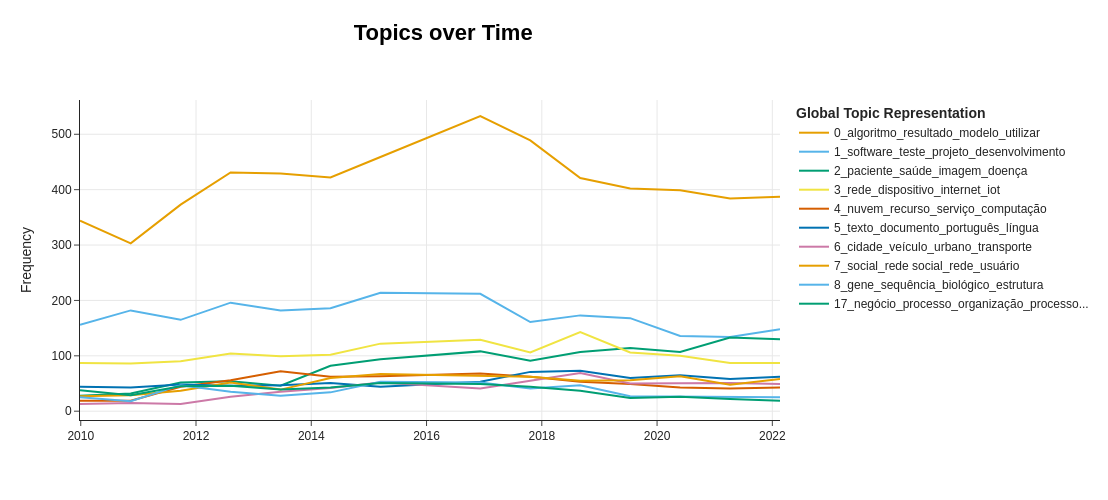

In [6]:
# 1. Cálculo de Tópicos ao Longo do Tempo nativo do BERTopic
anos = df['AN_BASE'].tolist()
topicos_no_tempo = topic_model.topics_over_time(documentos, anos, nr_bins=15)

# Visualização interativa (Plotly) dos 10 maiores tópicos
fig_tempo = topic_model.visualize_topics_over_time(topicos_no_tempo, top_n_topics=10, width=950, height=500)
fig_tempo.show()

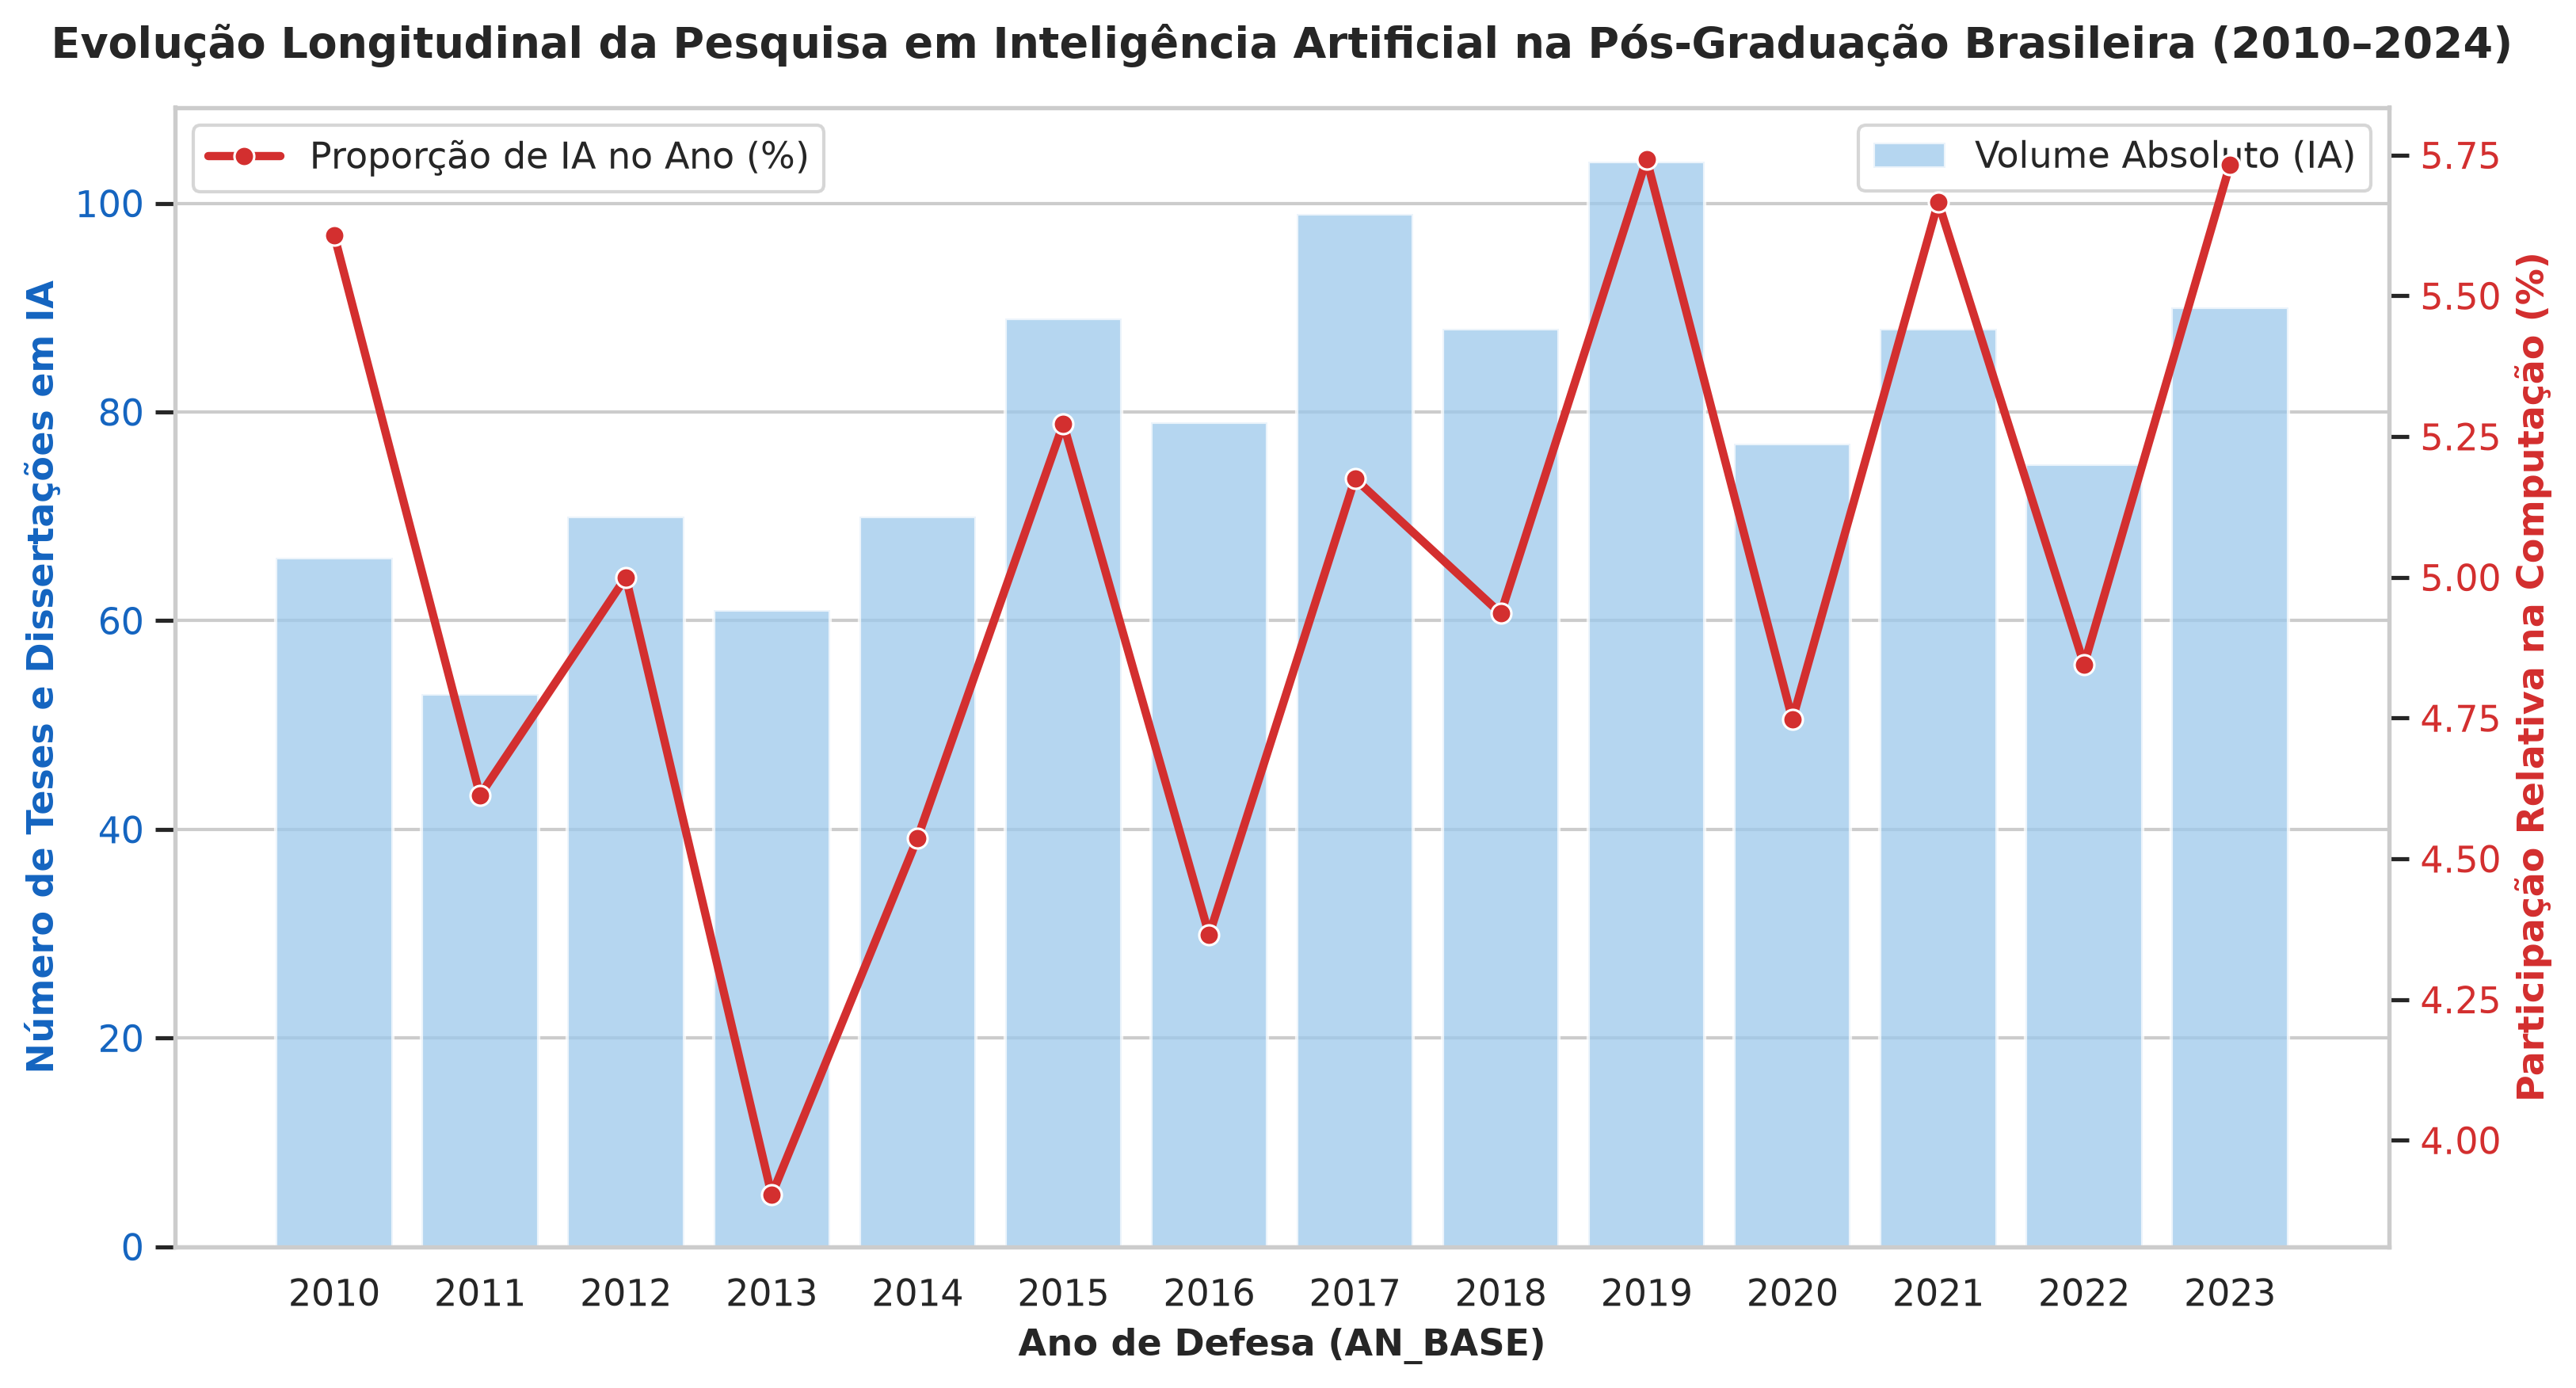

,AN_BASE,total_trabalhos,trabalhos_ia,proporcao_ia
0,2010,1177,66,5.607477
1,2011,1149,53,4.612707
2,2012,1400,70,5.000000
3,2013,1563,61,3.902751
4,2014,1543,70,4.536617
5,2015,1688,89,5.272512
6,2016,1810,79,4.364641
7,2017,1913,99,5.175118
8,2018,1783,88,4.935502
9,2019,1811,104,5.742684


In [7]:
# 2. Gráfico Estático em Alta Resolução (Padrão Artigo SBC / Educomp)
evolucao_anual = df.groupby('AN_BASE').agg(
    total_trabalhos=('IS_IA', 'count'),
    trabalhos_ia=('IS_IA', 'sum')
).reset_index()

evolucao_anual['proporcao_ia'] = (evolucao_anual['trabalhos_ia'] / evolucao_anual['total_trabalhos']) * 100

fig, ax1 = plt.subplots(figsize=(11, 6), dpi=300)

# Barras para o volume absoluto de teses/dissertações em IA
sns.barplot(data=evolucao_anual, x='AN_BASE', y='trabalhos_ia', color='#90caf9', alpha=0.75, ax=ax1, label='Volume Absoluto (IA)')
ax1.set_ylabel('Número de Teses e Dissertações em IA', fontsize=11, color='#1565c0', fontweight='bold')
ax1.set_xlabel('Ano de Defesa (AN_BASE)', fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#1565c0')

# Linha no eixo secundário para a representatividade percentual (%)
ax2 = ax1.twinx()
sns.lineplot(
    data=evolucao_anual, 
    x=range(len(evolucao_anual)), 
    y='proporcao_ia', 
    color='#d32f2f', 
    marker='o', 
    linewidth=2.5, 
    ax=ax2, 
    label='Proporção de IA no Ano (%)'
)
ax2.set_ylabel('Participação Relativa na Computação (%)', fontsize=11, color='#d32f2f', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#d32f2f')
ax2.grid(False)

plt.title('Evolução Longitudinal da Pesquisa em Inteligência Artificial na Pós-Graduação Brasileira (2010–2024)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../data/grafico_evolucao_ia_2010_2024.png', dpi=300)
plt.show()

evolucao_anual

## 6. Análise Educacional: Recorte Geográfico e Nível Acadêmico
Para enriquecer a discussão pedagógica e de políticas públicas no **Educomp**, cruzamos os resultados da modelagem de tópicos com a região geográfica (`NM_REGIAO`) e o nível do curso (`NM_GRAU_ACADEMICO`).

In [8]:
# Distribuição Regional da produção em IA vs Outras Áreas
regiao_ia = df.groupby('NM_REGIAO').agg(
    Total=('IS_IA', 'count'),
    Trabalhos_IA=('IS_IA', 'sum'),
    Percentual_IA=('IS_IA', lambda x: round(x.mean() * 100, 2))
).sort_values(by='Total', ascending=False).reset_index()

print("Distribuição da Produção Científica e Foco em IA por Região:")
display(regiao_ia)

# Comparação por Grau Acadêmico (Mestrado vs Doutorado)
grau_ia = df.groupby('NM_GRAU_ACADEMICO').agg(
    Total=('IS_IA', 'count'),
    Trabalhos_IA=('IS_IA', 'sum'),
    Percentual_IA=('IS_IA', lambda x: round(x.mean() * 100, 2))
).sort_values(by='Total', ascending=False).reset_index()

print("\nDistribuição por Grau Acadêmico:")
display(grau_ia)

Distribuição da Produção Científica e Foco em IA por Região:


,NM_REGIAO,Total,Trabalhos_IA,Percentual_IA
0,SUDESTE,9396,477,5.08
1,NORDESTE,6476,230,3.55
2,SUL,4405,237,5.38
3,CENTRO-OESTE,1094,116,10.60
4,NORTE,759,49,6.46



Distribuição por Grau Acadêmico:


,NM_GRAU_ACADEMICO,Total,Trabalhos_IA,Percentual_IA
0,MESTRADO,13040,613,4.70
1,DOUTORADO,3720,181,4.87
2,Mestrado,3069,156,5.08
3,MESTRADO PROFISSIONAL,1639,126,7.69
4,Doutorado,479,31,6.47
5,Profissionalizante,178,2,1.12
6,DOUTORADO PROFISSIONAL,5,0,0.00


## 7. Exportação da Base Rotulada para a Etapa 3 (Classificação Supervisionada)
Salvamos o dataset enriquecido com as colunas `TOPICO_ID`, `TOPICO_NOME` e `IS_IA` diretamente em formato compactado `.csv.gz` (respeitando o limite do GitHub). 

In [9]:
caminho_saida_topicos = '../data/dados_capes_topicos_ia.csv.gz'
df.to_csv(caminho_saida_topicos, index=False, encoding='utf-8', compression='gzip')

# Salva também a tabela resumo de todos os tópicos para colocar como tabela no artigo LaTeX
info_topicos.to_csv('../data/tabela_resumo_topicos_bertopic.csv.gz', index=False, encoding='utf-8', compression='gzip')

print(f"Base rotulada salva com sucesso em: {caminho_saida_topicos}")
print("Pronto para a Etapa 3: Treinamento de Classificadores Supervisionados (Random Forest, SVM, GBM)!")

Base rotulada salva com sucesso em: ../data/dados_capes_topicos_ia.csv.gz
Pronto para a Etapa 3: Treinamento de Classificadores Supervisionados (Random Forest, SVM, GBM)!
